In [1]:
import os
import sys
import importlib
sys.path.append(os.path.relpath("../src"))
import convAE
import torch
from torchinfo import summary
import torch.nn as nn

In [19]:
importlib.reload(convAE)
dir_path = "/feynman/work/projets/cupid/data/LSM/RUN9/"
file_paths = [dir_path + "000813_20230628T161508_{:03}_000.bin".format(i) for i in [3, 5, 9, 11, 13, 15, 17, 19]]

n_channel = 2 * len(file_paths)
channel_guess = 7
win_length = 4095
n_fft = 512
start_window = 1024
end_window = 1024 * 3
out_window_size = end_window - start_window
hop_length = 64

# Load the model
hyperparameters_dict = {"filters": [16, 32, 64, 128, 256, 512, 1024], "kernel_size": [1, 3], "strides": [1, 2], "n_LSTM": 2, "LSTM_group_number": 91, "hop_length": 128, "win_length": 4096, "n_fft": 960, "out_window_size": 2048, "n_in": 16, "n_out": 1, "unknown_window_center": 0.5}
# hyperparameters_dict = dict(filters=[16, 32, 64, 128, 256], kernel_size=(1, 3), strides=(1, 2),
#                             n_LSTM=3, LSTM_group_number=4,
#                             hop_length=hop_length, win_length=win_length, n_fft=n_fft, out_window_size=out_window_size,
#                             n_in=n_channel, n_out=1)
# hyperparameters_dict = dict(filters=[16, 32, 64, 128, 256], kernel_size=(1, 3), strides=(1, 2),
#                             hop_length=hop_length, win_length=win_length, n_fft=n_fft, out_window_size=out_window_size,
#                             n_in=n_channel, n_out=1)
model = convAE.AutoencoderLSTM(**hyperparameters_dict)
print(summary(model, [2,*model.Input_shape]))
print(model.Input_shape)
# x = torch.rand([2,*model.Input_shape])
# print(model(x).dtype)
# i=1

latent_space_size:  2


OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detect OpenMP Loop and this application may hang. Please rebuild the library with USE_OPENMP=1 option.
OpenBLAS Warning : Detec

Layer (type:depth-idx)                   Output Shape              Param #
AutoencoderLSTM                          [2, 2048]                 --
├─ModuleList: 1-13                       --                        (recursive)
│    └─Conv2d: 2-1                       [2, 16, 33, 240]          784
├─ELU: 1-2                               [2, 16, 33, 240]          --
├─ModuleList: 1-13                       --                        (recursive)
│    └─Conv2d: 2-2                       [2, 32, 33, 119]          1,568
├─ELU: 1-4                               [2, 32, 33, 119]          --
├─ModuleList: 1-13                       --                        (recursive)
│    └─Conv2d: 2-3                       [2, 64, 33, 59]           6,208
├─ELU: 1-6                               [2, 64, 33, 59]           --
├─ModuleList: 1-13                       --                        (recursive)
│    └─Conv2d: 2-4                       [2, 128, 33, 29]          24,704
├─ELU: 1-8                            

In [13]:
from training_CUPID import create_data_sets
import json
dir_train = "/feynman/work/projets/cupid/scratch/mpageot/data/trainings/opt_AutoencoderLSTM_RUN9_813_channel19/trial_124"
with open(os.path.join(dir_train, "InfoDict.json"), "r") as out_file:
    InfoDict = json.load(out_file)
dataset_dict = InfoDict["dataset_dict"]
data_spliting_dict = InfoDict["data_spliting_dict"]
dataset_dict, train_loader, val_loader, test_loader = create_data_sets(dataset_dict, data_spliting_dict)


In [76]:
model.Input_shape

(16, 26, 129)

In [73]:
hyperparameters_dict = {'filters': [16, 32, 64, 128, 256], 'kernel_size': [1, 3], 'strides': [1, 2], 'n_LSTM': 6, 'LSTM_group_number': 14,
                        'hop_length': 160, 'win_length': 4096, 'n_fft': 256, 'out_window_size': 2048, 'n_in': 16, 'n_out': 1,
                        'unknown_window_center': 0.5}
x= torch.rand(hyperparameters_dict["win_length"])
torch.stft(x, n_fft=hyperparameters_dict["n_fft"], hop_length=hyperparameters_dict["hop_length"],win_length=hyperparameters_dict["n_fft"], onesided=True,center=True,
                                  return_complex=False).shape



torch.Size([129, 26, 2])

In [23]:
sys.path.append(os.path.relpath("../src"))
import dataloader as dl
from torch.utils.data import DataLoader
import numpy as np
from torch.autograd import gradcheck


In [15]:
importlib.reload(dl)
position = torch.load("/feynman/work/projets/cupid/scratch/mpageot/data/pos_start_813_3_5_9_11_13_15_17_19.pt")
print(model.Input_shape)
STFT_dataset = dl.DatasetSTFTFromBinary(file_paths,position,win_length,
                                       start_window=1024, end_window=1024*3,channel_out=0,
                                        n_fft=n_fft, hop_length=hop_length, dtype=np.uint32)
file_path = "/feynman/work/projets/cupid/scratch/mpageot/python_project/Denoising/data/data_813_3_5_9_11_13_15_17_19.npy"

npy_dataset = dl.DatasetSTFTFromNpy(file_path, win_length,
                 n_fft, hop_length, channel_out=0, start_window=1024, end_window=1024*3)
dataloader = DataLoader(npy_dataset, batch_size=32, shuffle=False)
for batch_idx, (X_batch,Y_batch) in enumerate(dataloader):
    print(f"Batch {batch_idx + 1}")
    print("X_batch shape:", X_batch.shape)
    print("Y_batch shape:", Y_batch.shape)
    print(model(X_batch).shape)
    if batch_idx == 2:
        break

(16, 64, 161)
torch.Size([2691, 8, 4095])
Batch 1
X_batch shape: torch.Size([32, 16, 64, 161])
Y_batch shape: torch.Size([32, 2048])
torch.Size([32, 64, 1024])
torch.Size([32, 2048])
Batch 2
X_batch shape: torch.Size([32, 16, 64, 161])
Y_batch shape: torch.Size([32, 2048])
torch.Size([32, 64, 1024])
torch.Size([32, 2048])
Batch 3
X_batch shape: torch.Size([32, 16, 64, 161])
Y_batch shape: torch.Size([32, 2048])
torch.Size([32, 64, 1024])
torch.Size([32, 2048])


In [15]:
data_spliting_dict = {'batch_size': 64}
if "batch_size" not in data_spliting_dict:
    data_spliting_dict["batch_size"] = 32
print(data_spliting_dict)

{'batch_size': 64}


In [28]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
str(device)

'cpu'

[I 2025-01-22 12:18:58,313] Using an existing study with name 'mse_f1' instead of creating a new one.
/tmp/ipykernel_1553785/1220909049.py:7: ExperimentalWarning: plot_contour is experimental (supported from v2.2.0). The interface can change in the future.
  fig = optuna.visualization.matplotlib.plot_contour(study, params=["window_size", "hidden_size","num_fc_layers"])
[W 2025-01-22 12:18:58,595] Output figures of this Matplotlib-based `plot_contour` function would be different from those of the Plotly-based `plot_contour`.


NameError: name 'scipy' is not defined

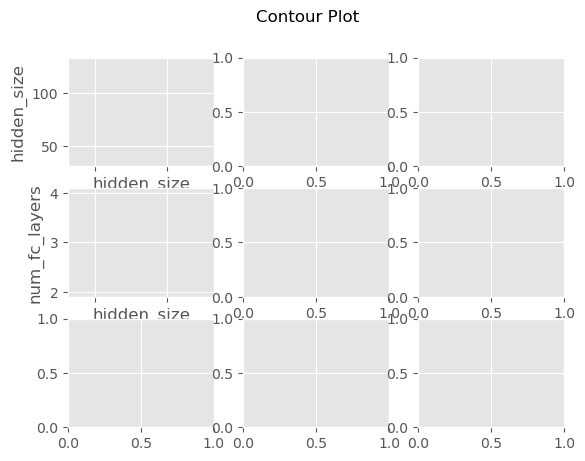

In [1]:
import optuna
from optuna.storages import RDBStorage
import matplotlib.pyplot as plt
database_url = "sqlite:////feynman/work/projets/cupid/data/data_simu/database/mse_f1_2.db"
storage = RDBStorage(url=database_url)
study = optuna.create_study(storage=storage, study_name='mse_f1', direction='maximize', load_if_exists=True)
fig = optuna.visualization.matplotlib.plot_contour(study, params=["window_size", "hidden_size","num_fc_layers"])


#optuna.visualization.matplotlib.plot_param_importances(study)
plt.show()
